---
title: "L3-03 · Matrices as transformations"
short_title: "Matrices as transformations"
subtitle: "A matrix is a recipe for moving the whole plane: its columns say where the basis vectors go, the determinant says how areas scale, and the unitary matrices are exactly the moves that keep every length and every inner product."
description: "Read a matrix as the transformation that sends the basis vectors to its columns, compose transformations in the right order, use the determinant as signed area scaling, and test whether a matrix is unitary."
tags: [level-3, coursebook]
---

(lesson-l3-03)=

:::{div}
:class: qcai-meta
![Level 3 icon](../../_static/icons/qicon-level-3.svg) **Level 3 · High-school bridge** · about 100 minutes  
**Big idea.** A matrix is a recipe for moving the whole plane: its columns say where the basis vectors go, the determinant says how areas scale, and the unitary matrices are exactly the moves that keep every length and every inner product.  
**Before this lesson.** [L3-02](#lesson-l3-02)  
**Lab.** [Qubits and the Bloch sphere](../../labs/05-qubit-bloch.ipynb)
:::

## What you will be able to do

- Compute $Mv$ and $AB$, and explain why the columns of $M$ are $Me_0$ and $Me_1$ and why $ABv$ means: apply $B$ first, then $A$.
- Compute a $2\times 2$ determinant, interpret its sign and size as orientation and area scaling, and use it to decide invertibility and write the inverse.
- Form the conjugate transpose $U^\dagger$, test $U^\dagger U = I$, and prove that this is equivalent to preserving inner products and to preserving norms.

## Why this matters

In [L3-02](#lesson-l3-02) you measured vectors. Now we move them. A quantum gate, a rotation of a robot arm, a layer of a neural network and a change of coordinates are all the same kind of object: a rule that sends every vector to a new vector and respects addition and scaling. Such a rule is completely fixed by where it sends the basis vectors, and writing those images side by side gives a matrix.

Two questions about these moves matter for everything later. Can the move be undone? (A camera that flattens a 3-D scene into a photo cannot be undone; a rotation can.) And does it keep lengths? Quantum states must stay normalized, so the moves allowed on a closed quantum system are exactly the length-keeping ones. A tempting shortcut is to think that a matrix with determinant 1 keeps lengths because it keeps area. The shear in this lesson shows that this is false, and the theorem at the end shows what the right test is.

:::{dropdown} Key terms

**Linear map**
: A function $M$ with $M(av + bw) = aMv + bMw$; on $\mathbb{C}^n$ every linear map is multiplication by a matrix.

**Matrix product**
: $(AB)_{jk} = \sum_m A_{jm}B_{mk}$; it is the matrix of the composite map $v \mapsto A(Bv)$.

**Determinant**
: For $\begin{pmatrix} a & b \\ c & d\end{pmatrix}$, $ad - bc$: the signed factor by which the map scales areas.

**Conjugate transpose**
: $U^\dagger$, obtained by turning rows into columns and conjugating every entry: $(U^\dagger)_{jk} = \overline{U_{kj}}$.

**Unitary matrix**
: A square matrix with $U^\dagger U = I$; real unitary matrices are called orthogonal.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l3_03 as _lessonfigs

## A matrix is where the basis vectors go

:::{prf:definition} Matrix times vector
:label: def-l3-03-matvec
For an $m\times n$ matrix $M$ and $v \in \mathbb{C}^n$, $\;(Mv)_j = \sum_{k=1}^{n} M_{jk} v_k$: each output entry is a row of $M$ times the column $v$. The number of columns of $M$ must equal the number of entries of $v$ [@openstax_matrices].
:::

:::{prf:proposition} Columns are images of the basis
:label: prop-l3-03-columns
The $k$-th column of $M$ is $Me_k$. Because $v = \sum_k v_k e_k$ and matrix multiplication is linear, $Mv = \sum_k v_k\,(Me_k)$: the image of any vector is the same combination of the columns.
:::

$$
\begin{pmatrix} a & b \\ c & d \end{pmatrix}\begin{pmatrix} x \\ y \end{pmatrix} = x\begin{pmatrix} a \\ c \end{pmatrix} + y\begin{pmatrix} b \\ d \end{pmatrix}
$$ (eq-l3-03-columns)

Equation [](#eq-l3-03-columns) is the picture to keep. Draw the grid of the plane; a matrix moves $e_0 = (1, 0)$ to its first column and $e_1 = (0, 1)$ to its second, and every grid line follows along, staying straight, parallel and evenly spaced. Four examples carry the whole lesson: the quarter turn $R = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}$, the shear $S = \begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix}$, the reflection $F = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$ and the collapse $C = \begin{pmatrix} 1 & 2 \\ 1/2 & 1 \end{pmatrix}$.

:::{figure} ../../_static/animations/l3_03_grid_transformations.mp4
:alt: The whole coordinate grid with a shaded unit square is turned a quarter turn, sheared, reflected and finally collapsed onto a line, with each matrix and its determinant shown.
:width: 100%

The grid under $R$, $S$, $F$ and $C$. The shaded unit square tracks the determinant: $\det R = 1$, $\det S = 1$, $\det F = -1$, $\det C = 0$.
:::

:::{dropdown} What the animation shows
A blue grid fills the screen with the unit square shaded and the basis vectors $e_0$ (purple) and $e_1$ (orange). A card explains that the columns of a matrix are where the basis vectors land. First the quarter turn $R$ rotates the whole grid by $90^\circ$: $e_0$ lands on $(0, 1)$ and $e_1$ on $(-1, 0)$; the card shows $\det R = 1$, area kept. The grid turns back. The shear $S$ slides each horizontal line sideways in proportion to its height, so the square becomes a parallelogram of the same area: $\det S = 1$. The reflection $F$ flips the grid in the horizontal axis; the square keeps its area but its orientation reverses: $\det F = -1$. Finally the collapse $C$ squeezes the entire plane onto the line through $(2, 1)$; the square becomes a segment of area zero, $\det C = 0$. A red arrow marks $(2, -1)$, which $C$ sends to $(0, 0)$, so no inverse can exist.
:::

## Composition: the order of the moves

:::{prf:definition} Matrix product
:label: def-l3-03-product
For an $m\times p$ matrix $A$ and a $p\times n$ matrix $B$, $(AB)_{jk} = \sum_{m'=1}^{p} A_{jm'} B_{m'k}$. Column $k$ of $AB$ is $A$ applied to column $k$ of $B$, so $(AB)v = A(Bv)$ for every $v$.
:::

$$
(AB)\,v = A\,(B\,v) \qquad \text{(apply } B \text{ first, then } A\text{)}
$$ (eq-l3-03-compose)

:::{figure} ../../_static/animations/l3_03_composition_order.mp4
:alt: The grid is sheared and then turned, giving RS; it is reset and then turned and sheared, giving SR; the basis vectors end in different places.
:width: 100%

Shear then turn ($RS$) versus turn then shear ($SR$). The final grids differ, so $RS \ne SR$.
:::

:::{dropdown} What the animation shows
The grid with its unit square first undergoes the shear $S$ and then the quarter turn $R$. The basis vectors end at the columns of $RS = \begin{pmatrix} 0 & -1 \\ 1 & 1 \end{pmatrix}$, namely $(0, 1)$ and $(-1, 1)$, which are marked with dots. The grid is reset. Now $R$ acts first and $S$ second; the basis vectors end at the columns of $SR = \begin{pmatrix} 1 & -1 \\ 1 & 0 \end{pmatrix}$, namely $(1, 1)$ and $(-1, 0)$, away from the dots. A card shows both products and the conclusion $RS \ne SR$.
:::

Compute it by rows times columns: $RS = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}\begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix} = \begin{pmatrix} 0 & -1 \\ 1 & 1 \end{pmatrix}$ and $SR = \begin{pmatrix} 1 & -1 \\ 1 & 0 \end{pmatrix}$. Matrix multiplication is associative, $(AB)C = A(BC)$, because composing functions is associative, but it is not commutative. In a quantum circuit drawn left to right, the gate drawn first is written rightmost in the product.

## The determinant: area, orientation and undoing

:::{prf:definition} Determinant of a two-by-two matrix
:label: def-l3-03-det
$\det\begin{pmatrix} a & b \\ c & d \end{pmatrix} = ad - bc$.
:::

:::{prf:proposition} Signed area scaling
:label: prop-l3-03-area
The unit square is sent to the parallelogram spanned by the columns $(a, c)$ and $(b, d)$. Its area is $|ad - bc|$, and $ad - bc < 0$ exactly when the map reverses orientation (it turns the counterclockwise order of $e_0, e_1$ into clockwise).
:::

:::{prf:proof}
Put the parallelogram with vertices $0$, $(a, c)$, $(a + b, c + d)$, $(b, d)$ into the shoelace formula: twice the signed area is $(a(c + d) - (a + b)c) + ((a + b)d - b(c + d)) = (ad - bc) + (ad - bc)$, so the signed area is $ad - bc$. Its sign is positive when $(b, d)$ lies counterclockwise from $(a, c)$, which is the orientation of $e_0, e_1$.
:::

:::{prf:theorem} Determinants multiply; the two-by-two inverse
:label: thm-l3-03-det
For $2\times 2$ matrices, $\det(AB) = \det A\,\det B$. A $2\times 2$ matrix $M = \begin{pmatrix} a & b \\ c & d \end{pmatrix}$ is invertible exactly when $\det M \ne 0$, and then $M^{-1} = \frac{1}{ad - bc}\begin{pmatrix} d & -b \\ -c & a \end{pmatrix}$.
:::

:::{prf:proof}
Let $B = \begin{pmatrix} e & f \\ g & h \end{pmatrix}$. Then $AB = \begin{pmatrix} ae + bg & af + bh \\ ce + dg & cf + dh \end{pmatrix}$ and $\det(AB) = (ae + bg)(cf + dh) - (af + bh)(ce + dg)$. The terms $acef$ and $bdgh$ cancel, leaving $adeh + bcfg - adfg - bceh = (ad - bc)(eh - fg)$. For the inverse, multiply: $\begin{pmatrix} a & b \\ c & d \end{pmatrix}\begin{pmatrix} d & -b \\ -c & a \end{pmatrix} = (ad - bc)\,I$, so dividing by $ad - bc \ne 0$ gives $M^{-1}$. If $\det M = 0$ and $M^{-1}$ existed, then $1 = \det I = \det M \det M^{-1} = 0$, a contradiction.
:::

For the four examples, $\det R = 1$, $\det S = 1$, $\det F = -1$ and $\det C = 0$. The collapse has columns $(1, 1/2)$ and $(2, 1)$, the second twice the first, so the whole plane lands on one line and $C(2, -1) = (2 - 2,\ 1 - 1) = (0, 0)$. Two different inputs, $(2, -1)$ and $(0, 0)$, have the same output, so no rule can recover the input: a zero determinant means information is lost.


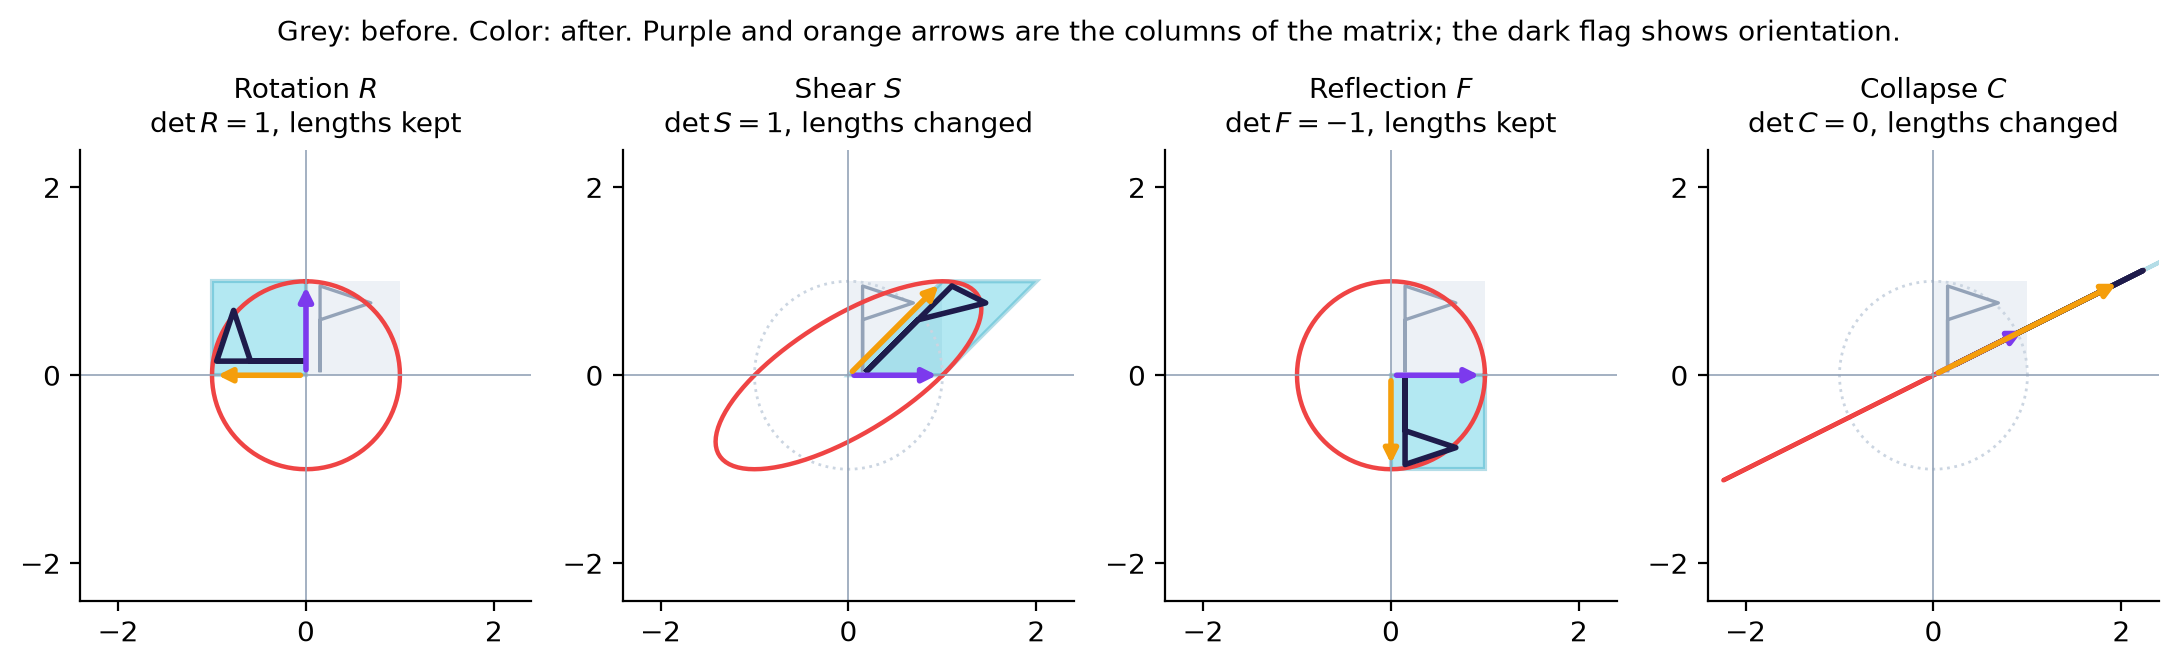

In [2]:
_show_mpl(_lessonfigs.transform_gallery())

*The same four matrices acting on the unit square (cyan), the unit circle (red) and a flag that shows orientation. Only $R$ and $F$ send the circle to itself; the shear stretches it into an ellipse even though $\det S = 1$.*

## Keeping lengths: unitary matrices

:::{figure} ../../_static/animations/l3_03_norm_preserving.mp4
:alt: Side by side, a rotation by 30 degrees and the shear S act on a point moving around the unit circle; the rotated length stays 1.000 while the sheared length swings between 0.618 and 1.618.
:width: 100%

A rotation keeps every length; the shear $S$, with the same determinant 1, stretches some directions to $1.618$ and shrinks others to $0.618$.
:::

:::{dropdown} What the animation shows
Two coordinate planes show the unit circle. On the left the rotation $R_{30}$ by $30^\circ$ maps it to itself; on the right the shear $S$ maps it to a tilted ellipse. A gray input arrow $x$ runs once around the circle, and colored arrows show $R_{30}x$ and $Sx$, with live readouts of their lengths. The rotated length stays 1.000 throughout. The sheared length varies; the animation stops at the longest image, length 1.618, and the shortest, length 0.618 (these are $(1 + \sqrt5)/2$ and its reciprocal). A final line notes that $\det S = 1$ although lengths change: keeping area is not keeping length.
:::

:::{prf:definition} Conjugate transpose and unitary matrix
:label: def-l3-03-unitary
The **conjugate transpose** of a matrix $A$ is $A^\dagger$ with $(A^\dagger)_{jk} = \overline{A_{kj}}$. A square matrix $U$ is **unitary** if $U^\dagger U = I$; then $U^{-1} = U^\dagger$. A real unitary matrix is called **orthogonal** ($U^{\mathsf T} U = I$).
:::

:::{prf:lemma} Moving a matrix across the inner product
:label: lem-l3-03-adjoint
For every matrix $A$ and vectors $u, v$ of matching sizes, $\langle Au, v\rangle = \langle u, A^\dagger v\rangle$.
:::

:::{prf:proof}
$\langle Au, v\rangle = \sum_j \overline{(Au)_j}\,v_j = \sum_j \sum_k \overline{A_{jk}}\,\overline{u_k}\,v_j = \sum_k \overline{u_k} \sum_j (A^\dagger)_{kj} v_j = \sum_k \overline{u_k}\,(A^\dagger v)_k = \langle u, A^\dagger v\rangle$.
:::

:::{prf:theorem} Three equivalent descriptions of unitarity
:label: thm-l3-03-unitary
For a square complex matrix $U$ the following are equivalent: (i) $U^\dagger U = I$; (ii) $\langle Uu, Uv\rangle = \langle u, v\rangle$ for all $u, v$; (iii) $\|Uv\| = \|v\|$ for all $v$.
:::

:::{prf:proof}
(i) implies (ii): by the lemma, $\langle Uu, Uv\rangle = \langle u, U^\dagger U v\rangle = \langle u, v\rangle$. (ii) implies (iii): take $u = v$. (iii) implies (ii): the polarization identity $\langle u, v\rangle = \frac14\sum_{k=0}^{3} i^{k}\,\|i^{k}u + v\|^2$ writes every inner product through norms (expand $\|i^k u + v\|^2 = \|u\|^2 + \|v\|^2 + 2\operatorname{Re}(i^{-k}\langle u, v\rangle)$ and sum). Since $U(i^k u + v) = i^k Uu + Uv$, preserving all norms preserves all inner products. (ii) implies (i): the $(j, k)$ entry of $U^\dagger U$ is $\langle e_j, U^\dagger U e_k\rangle = \langle U e_j, U e_k\rangle = \langle e_j, e_k\rangle = \delta_{jk}$, which is the $(j, k)$ entry of $I$.
:::

$$
U^\dagger U = I \iff \|Uv\| = \|v\| \text{ for every } v
$$ (eq-l3-03-unitary)

Equivalently, $U$ is unitary exactly when its columns form an orthonormal basis, because the $(j, k)$ entry of $U^\dagger U$ is the inner product of column $j$ with column $k$. Check the Hadamard matrix $H = \frac{1}{\sqrt2}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$: its columns $(1, 1)/\sqrt2$ and $(1, -1)/\sqrt2$ are the orthonormal basis $e_\pm$ of [L3-02](#lesson-l3-02). Applied to $(1, 0)$ it gives $(1/\sqrt2, 1/\sqrt2)$; applied again it gives $(1, 0)$, because $H^2 = I$. The phase matrix $P = \begin{pmatrix} 1 & 0 \\ 0 & i \end{pmatrix}$ is unitary but has no real picture as a rotation of the plane: it rotates the second complex amplitude by $90^\circ$ in its own complex plane. The shear fails the test: $S^{\mathsf T} S = \begin{pmatrix} 1 & 1 \\ 1 & 2 \end{pmatrix} \ne I$, and indeed $\|S e_1\| = \|(1, 1)\| = \sqrt2$.

```{mermaid}
graph TD
  A[All square matrices] --> B[Invertible: det ≠ 0]
  B --> U[Unitary: keeps lengths]
  U --> O[Real orthogonal]
  O --> Rot[Rotations: det 1]
  O --> Ref[Reflections: det -1]
  B --> Sh[Shear S: det 1, not unitary]
```

*How the classes of matrices in this lesson nest. Unitary matrices are invertible ($U^{-1} = U^\dagger$, $|\det U| = 1$); real orthogonal $2\times 2$ matrices are rotations or reflections. The shear is invertible with determinant 1 but is not unitary.*


In [3]:
_show(_lessonfigs.matrix_explorer())

**Explore.** Choose a matrix from the menu. The cyan shape is the image of the unit square, the red curve the image of the unit circle, and the arrows are the two columns. The title gives the determinant and whether all lengths are kept.

:::{dropdown} What the figure shows
A single plot shows the dotted unit square and unit circle and their images under the chosen matrix, with the columns $Me_0$ and $Me_1$ as purple and orange arrows. The menu offers the identity, a rotation by $30^\circ$, the shear $S$ (determinant 1, lengths change), the reflection $F$ (determinant $-1$, lengths kept), the collapse $C$ (determinant 0; square and circle flatten onto a line), a stretch $\operatorname{diag}(2, 1/2)$ (determinant 1, lengths change) and the Hadamard matrix $H$ (determinant $-1$, lengths kept). Only the matrices that keep lengths send the circle to itself.
:::

:::{caution} Unitary is not the same as stochastic
A stochastic matrix such as $T = \begin{pmatrix} 0.9 & 0.2 \\ 0.1 & 0.8 \end{pmatrix}$ (non-negative entries, columns summing to 1) keeps the **sum** of a probability vector: $T(0.5, 0.5) = (0.55, 0.45)$. It does not keep the length: $\|(0.5, 0.5)\| \approx 0.707$ but $\|(0.55, 0.45)\| \approx 0.711$. Unitary matrices keep the length of amplitude vectors, which is what normalization of quantum states requires. Closed quantum systems evolve by unitary matrices; measurement and noise need the more general descriptions of Level 5 [@nielsenchuang; @watrous].
:::

NumPy's `@` is the matrix product and `M.conj().T` is $M^\dagger$. The cell checks every claim of the lesson: columns, determinants, $RS \ne SR$, the inverse formula, the shear's stretch factors, unitarity tests and a stochastic matrix.


In [4]:
import numpy as np

R = np.array([[0, -1], [1, 0]])        # quarter turn
S = np.array([[1, 1], [0, 1]])         # shear
F = np.array([[1, 0], [0, -1]])        # reflection in the x axis
C = np.array([[1, 2], [0.5, 1]])       # collapse onto a line
e0, e1 = np.array([1, 0]), np.array([0, 1])

# columns are the images of the basis vectors
print('R e0 =', R @ e0, ' R e1 =', R @ e1, ' (the columns of R)')
for name, M in (('R', R), ('S', S), ('F', F), ('C', C)):
    print(f'det {name} = {np.linalg.det(M):+.3f}')
print('C (2, -1) =', C @ np.array([2, -1]), ' so C squashes a whole line to 0')

# order matters
print('RS =', (R @ S).tolist(), '  SR =', (S @ R).tolist())
v = np.array([1, 2])
assert np.allclose((R @ S) @ v, R @ (S @ v))      # RS v means: S first, then R

# 2 x 2 inverse from the determinant
A = np.array([[3, 1], [4, 2]])
Ainv = np.array([[2, -1], [-4, 3]]) / np.linalg.det(A)
print('det A =', round(np.linalg.det(A), 6), ' A^{-1} =', Ainv.tolist(), ' check', np.allclose(A @ Ainv, np.eye(2)))

# det S = 1, yet S changes lengths: singular values are the extreme stretch factors
print('|S e1| =', np.linalg.norm(S @ e1), '  singular values of S:', np.linalg.svd(S, compute_uv=False).round(3))

# unitary matrices: U^dagger U = I
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
P = np.array([[1, 0], [0, 1j]])
U = np.array([[1, 1j], [1j, 1]]) / np.sqrt(2)
for name, M in (('H', H), ('P', P), ('U', U), ('S', S)):
    print(name, 'unitary:', np.allclose(M.conj().T @ M, np.eye(2)), '  |det| =', round(abs(np.linalg.det(M)), 6))
print('H(1,0) =', (H @ e0).round(4), '  H H (1,0) =', (H @ H @ e0).round(10))

# a random complex vector keeps its norm under U, and inner products are kept too
rng = np.random.default_rng(3)
x = rng.normal(size=2) + 1j * rng.normal(size=2)
y = rng.normal(size=2) + 1j * rng.normal(size=2)
print('norms:', round(np.linalg.norm(x), 6), round(np.linalg.norm(U @ x), 6),
      '  inner products equal:', np.isclose(np.vdot(U @ x, U @ y), np.vdot(x, y)))

# a stochastic matrix keeps the SUM of a probability vector, not its length
T = np.array([[0.9, 0.2], [0.1, 0.8]])
p = np.array([0.5, 0.5])
print('T p =', T @ p, ' sum', (T @ p).sum(), '  lengths', round(np.linalg.norm(p), 4), round(np.linalg.norm(T @ p), 4))

R e0 = [0 1]  R e1 = [-1  0]  (the columns of R)
det R = +1.000
det S = +1.000
det F = -1.000
det C = +0.000
C (2, -1) = [0. 0.]  so C squashes a whole line to 0
RS = [[0, -1], [1, 1]]   SR = [[1, -1], [1, 0]]
det A = 2.0  A^{-1} = [[1.0, -0.5], [-2.0, 1.5]]  check True
|S e1| = 1.4142135623730951   singular values of S: [1.618 0.618]
H unitary: True   |det| = 1.0
P unitary: True   |det| = 1.0
U unitary: True   |det| = 1.0
S unitary: False   |det| = 1.0
H(1,0) = [0.7071 0.7071]   H H (1,0) = [ 1. -0.]
norms: 3.345735 3.345735   inner products equal: True
T p = [0.55 0.45]  sum 1.0   lengths 0.7071 0.7106


## Worked example

:::{admonition} A beam-splitter matrix
:class: tip

Let $U = \frac{1}{\sqrt2}\begin{pmatrix} 1 & i \\ i & 1 \end{pmatrix}$. Show that $U$ is unitary, compute $U(1, 0)$ and $U(1, 1)/\sqrt2$, and find $\det U$.

1. Conjugate transpose: transposing changes nothing here (the matrix is symmetric), and conjugating turns $i$ into $-i$, so $U^\dagger = \frac{1}{\sqrt2}\begin{pmatrix} 1 & -i \\ -i & 1 \end{pmatrix}$.
2. Product: $U^\dagger U = \frac12\begin{pmatrix} 1\cdot 1 + (-i)(i) & 1\cdot i + (-i)\cdot 1 \\ (-i)\cdot 1 + 1\cdot i & (-i)(i) + 1\cdot 1 \end{pmatrix} = \frac12\begin{pmatrix} 2 & 0 \\ 0 & 2 \end{pmatrix} = I$. So $U$ is unitary. (Equivalently its columns $(1, i)/\sqrt2$ and $(i, 1)/\sqrt2$ are orthonormal; their inner product is $\bar 1\cdot i + \bar i\cdot 1 = 0$, as in [L3-02](#lesson-l3-02).)
3. Images: $U(1, 0) = \frac{1}{\sqrt2}(1, i)$, with squared norm $\frac12(1 + 1) = 1$. And $U\frac{1}{\sqrt2}(1, 1) = \frac12(1 + i,\ i + 1) = \frac{1 + i}{\sqrt2}\cdot\frac{1}{\sqrt2}(1, 1)$: the input is only multiplied by the unit complex number $\frac{1 + i}{\sqrt2} = e^{i\pi/4}$, so its norm stays 1.
4. Determinant: $\det U = \frac12(1\cdot 1 - i\cdot i) = \frac12(1 + 1) = 1$, consistent with $|\det U| = 1$ for every unitary matrix.

**Result.** $U$ is unitary with $U^{-1} = U^\dagger$ and $\det U = 1$. It sends $(1, 0)$ to the equal-weight vector $(1, i)/\sqrt2$, the matrix of an ideal 50:50 beam splitter in one common convention.
:::

## Exercises

**1. (Core)** Apply $H = \frac{1}{\sqrt2}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$ to $v = (1, 0)$. Then apply $H$ once more. Check the norm after each step.

:::{dropdown} Solution
$Hv = \frac{1}{\sqrt2}(1, 1)$, with norm $\sqrt{\frac12 + \frac12} = 1$. Then $H(Hv) = \frac12(1 + 1,\ 1 - 1) = (1, 0)$: the second entry cancels. The norm is again 1, and $H^2 = I$.
:::

**2. (Core)** Write the matrix $M$ that sends $e_0$ to $(2, 1)$ and $e_1$ to $(1, 3)$. Compute $M(1, -1)$ and $\det M$.

:::{dropdown} Solution
The columns are the images: $M = \begin{pmatrix} 2 & 1 \\ 1 & 3 \end{pmatrix}$. Then $M(1, -1) = 1\cdot(2, 1) - 1\cdot(1, 3) = (1, -2)$, and $\det M = 2\cdot 3 - 1\cdot 1 = 5$: areas grow by a factor of 5 and orientation is kept.
:::

**3. (Stretch)** Find $\det A$ and $A^{-1}$ for $A = \begin{pmatrix} 3 & 1 \\ 4 & 2 \end{pmatrix}$ and check $AA^{-1} = I$.

:::{dropdown} Solution
$\det A = 3\cdot 2 - 1\cdot 4 = 2$. So $A^{-1} = \frac12\begin{pmatrix} 2 & -1 \\ -4 & 3 \end{pmatrix} = \begin{pmatrix} 1 & -1/2 \\ -2 & 3/2 \end{pmatrix}$. Check: first row of $AA^{-1}$ is $(3 - 2,\ -3/2 + 3/2) = (1, 0)$, second row is $(4 - 4,\ -2 + 3) = (0, 1)$.
:::

**4. (Stretch)** Show that the shear $S = \begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix}$ is not unitary in two ways: by computing $S^{\mathsf T}S$, and by finding a unit vector whose image is longer than 1. Is $S$ invertible?

:::{dropdown} Solution
$S^{\mathsf T}S = \begin{pmatrix} 1 & 0 \\ 1 & 1 \end{pmatrix}\begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix} = \begin{pmatrix} 1 & 1 \\ 1 & 2 \end{pmatrix} \ne I$. The unit vector $e_1$ goes to $(1, 1)$, of length $\sqrt2 > 1$. Yes, $S$ is invertible: $\det S = 1$ and $S^{-1} = \begin{pmatrix} 1 & -1 \\ 0 & 1 \end{pmatrix}$ (shear back). Invertible does not imply unitary.
:::

**5. (Stretch)** For $R = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}$ and $S = \begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix}$ compute $RS$ and $SR$ and apply each to $(1, 0)$. Interpret the results as sequences of moves.

:::{dropdown} Solution
$RS = \begin{pmatrix} 0 & -1 \\ 1 & 1 \end{pmatrix}$ and $SR = \begin{pmatrix} 1 & -1 \\ 1 & 0 \end{pmatrix}$. $RS(1, 0) = (0, 1)$: the shear leaves $(1, 0)$ alone, then the turn sends it to $(0, 1)$. $SR(1, 0) = (1, 1)$: the turn sends $(1, 0)$ to $(0, 1)$, then the shear moves it to $(1, 1)$. Different order, different result.
:::

**6. (Challenge)** Prove that every real $2\times 2$ orthogonal matrix ($Q^{\mathsf T}Q = I$) is either a rotation $\begin{pmatrix} \cos t & -\sin t \\ \sin t & \cos t \end{pmatrix}$ (determinant 1) or a reflection $\begin{pmatrix} \cos t & \sin t \\ \sin t & -\cos t \end{pmatrix}$ (determinant $-1$).

:::{dropdown} Solution
$Q^{\mathsf T}Q = I$ says the columns are orthonormal. The first column is a unit vector, so it equals $(\cos t, \sin t)$ for some $t$. The second column is a unit vector orthogonal to it; in the plane there are exactly two, $(-\sin t, \cos t)$ and $(\sin t, -\cos t)$. The first choice gives the rotation, with determinant $\cos^2 t + \sin^2 t = 1$; the second gives the reflection, with determinant $-\cos^2 t - \sin^2 t = -1$ (it is the reflection in the line at angle $t/2$).
:::

**7. (Challenge)** Show that $|\det U| = 1$ for every $2\times 2$ unitary matrix $U$. You may use $\det(AB) = \det A\det B$ and $\det(A^\dagger) = \overline{\det A}$.

:::{dropdown} Solution
For $A = \begin{pmatrix} a & b \\ c & d \end{pmatrix}$, $A^\dagger = \begin{pmatrix} \bar a & \bar c \\ \bar b & \bar d \end{pmatrix}$ has determinant $\bar a\bar d - \bar c\bar b = \overline{ad - bc}$, which confirms the hint. Then $1 = \det I = \det(U^\dagger U) = \det U^\dagger\,\det U = \overline{\det U}\,\det U = |\det U|^2$, so $|\det U| = 1$. Examples: $\det H = -1$, $\det P = i$, and the beam splitter has $\det U = 1$.
:::

## Check your understanding

**1. A matrix $M$ sends $e_0 = (1, 0)$ to $(2, 5)$ and $e_1 = (0, 1)$ to $(-1, 3)$. What is $M$?**

- **A.** $\begin{pmatrix} 3 & -1 \\ 5 & 2 \end{pmatrix}$
- **B.** $\begin{pmatrix} 2 & 5 \\ -1 & 3 \end{pmatrix}$
- **C.** $\begin{pmatrix} 2 & -1 \\ 5 & 3 \end{pmatrix}$
- **D.** $\begin{pmatrix} -1 & 2 \\ 3 & 5 \end{pmatrix}$

:::{dropdown} Show the answer
**C. $\begin{pmatrix} 2 & -1 \\ 5 & 3 \end{pmatrix}$**

The columns of $M$ are the images of the basis vectors, so $(2, 5)$ is the first column and $(-1, 3)$ the second. Writing the images as rows gives the transpose, a different map.
:::

**2. A $2\times 2$ real matrix has determinant $-1$. What does it do to the unit square?**

- **A.** Doubles its area
- **B.** Keeps its area and reverses its orientation
- **C.** Shrinks it to a segment
- **D.** Keeps both its area and its orientation

:::{dropdown} Show the answer
**B. Keeps its area and reverses its orientation**

$|\det| = 1$ means areas are unchanged, and a negative sign means orientation is reversed, as for the reflection $F$.
:::

**3. Which matrix keeps the length of every vector?**

- **A.** $\begin{pmatrix} 2 & 0 \\ 0 & 1/2 \end{pmatrix}$
- **B.** $\begin{pmatrix} 1 & 1 \\ 0 & 1 \end{pmatrix}$
- **C.** $\frac{1}{\sqrt2}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$
- **D.** $\begin{pmatrix} 0.9 & 0.2 \\ 0.1 & 0.8 \end{pmatrix}$

:::{dropdown} Show the answer
**C. $\frac{1}{\sqrt2}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$**

The Hadamard matrix has orthonormal columns, so $H^\dagger H = I$ and it keeps all lengths. The shear and the stretch have determinant 1 but change lengths; the stochastic matrix keeps sums of probability vectors, not lengths.
:::

**4. What is $\langle v, v\rangle$ for $v = (1, i)$?** *(Review of [L3-02](#lesson-l3-02))*

- **A.** $1 + i$
- **B.** 2
- **C.** 0
- **D.** $2i$

:::{dropdown} Show the answer
**B. 2**

$\langle v, v\rangle = \bar 1\cdot 1 + \bar i\cdot i = 1 + 1 = 2$. Without the conjugate one would get $1 + i^2 = 0$.
:::

## Common misconceptions

- **"A matrix with determinant 1 keeps lengths."** Determinant 1 means areas are kept. The shear $S$ has $\det S = 1$ but sends the unit vector $e_1$ to $(1, 1)$ of length $\sqrt2$. Lengths are kept exactly when $U^\dagger U = I$.
- **"$AB$ and $BA$ are the same, as with numbers."** Matrix products compose moves, and the order of moves matters: $RS = \begin{pmatrix} 0 & -1 \\ 1 & 1 \end{pmatrix}$ but $SR = \begin{pmatrix} 1 & -1 \\ 1 & 0 \end{pmatrix}$. Also, $ABv$ applies $B$ first.
- **"The product of two matrices multiplies matching entries."** That is the entrywise (Hadamard) product, a different operation. The matrix product pairs rows of the first with columns of the second, $(AB)_{jk} = \sum_m A_{jm}B_{mk}$, because it must represent doing one map after the other.
- **"A matrix with non-negative entries whose columns sum to 1 is a valid quantum gate."** That describes a stochastic matrix, which keeps the total of a probability vector. Quantum gates must keep the length of amplitude vectors, which requires $U^\dagger U = I$; the stochastic matrix $T$ in this lesson changes lengths.

:::{caution} Scope and limits
This lesson uses column vectors, matrices acting from the left, and basis order $e_0, e_1$; with row vectors every product is reversed. Determinants and inverses are treated only for $2\times 2$ matrices, where the area argument can be drawn; the multiplicativity of determinants holds in every dimension, but the proof here is the $2\times 2$ computation. The equivalence of unitarity with norm preservation is for linear maps on finite-dimensional complex spaces. Unitary evolution describes closed quantum systems only; the effect of measurement or noise on a subsystem cannot be written as a single unitary matrix acting on that subsystem alone.
:::

:::{seealso} Where this leads
Tensor products in [L3-04](#lesson-l3-04) combine matrices acting on separate systems into one matrix $A\otimes B$ on the joint system. Eigenvectors in [L3-05](#lesson-l3-05) are the directions a matrix only stretches. In Level 5 every quantum gate is a unitary matrix, and the order rule $(AB)v = A(Bv)$ is how circuits are multiplied out.
:::

:::{dropdown} For instructors

**Why this lesson.** Students usually meet matrices as tables to multiply. Quantum information needs them as moves of a space, judged by what they preserve. The grid picture makes columns, composition order and determinants visible, and the shear gives a memorable counterexample that separates area preservation from length preservation [@openstax_matrices; @mml; @nielsenchuang].

**Teaching notes.**

- Before any multiplication, have students predict where $e_0$ and $e_1$ go under a quarter turn and write those images as columns; this makes the column rule a discovery rather than a convention.
- Act out composition with two transparencies or two phone gestures: shear then turn versus turn then shear. Then compute $RS$ and $SR$ to confirm.
- Use the interactive menu to ask which matrices keep the circle a circle; students should find that the stretch and the shear, both with determinant 1, do not.
- Spend time on the polarization step of the unitarity theorem; it is the reason checking lengths alone is enough.

**Assessment.** The second core exercise and the first check question test the column rule; the composition exercise and the misconception about $AB = BA$ test order; the shear exercise and the third check question test the difference between invertible, determinant 1 and unitary. The orthogonal-matrix challenge shows whether students can turn $Q^{\mathsf T}Q = I$ into geometry.

**Going further.** Show that the $3\times 3$ determinant equals the signed volume of the parallelepiped spanned by the columns, and that a rotation about the $z$ axis has determinant 1. Then prove that the product of two unitary matrices is unitary, $(UV)^\dagger(UV) = V^\dagger U^\dagger U V = I$. Mathematics for Machine Learning, chapter 2 and section 4.1, covers matrices and determinants [@mml].

:::

## References

This lesson draws on [@openstax_matrices; @mml; @nielsenchuang; @watrous; @ibm].

**Further reading.**

- [@ibm]: The Basics of quantum information course introduces unitary operations on qubits with worked matrices.
- [@mml]: Chapter 2 and section 4.1: matrices, linear maps and determinants.

**Next:** [L3-04 · Tensor products and joint systems](#lesson-l3-04)
